# ParFlow Short Course: Box domain from database

### Problem Description
The box model used here will follow the same setup as `box_domain_setup_full.ipynb` (see illustration below).  Instead of setting all the keys though we are going to practice reading in the database of keys from an existing run and using that to seed our setup. 
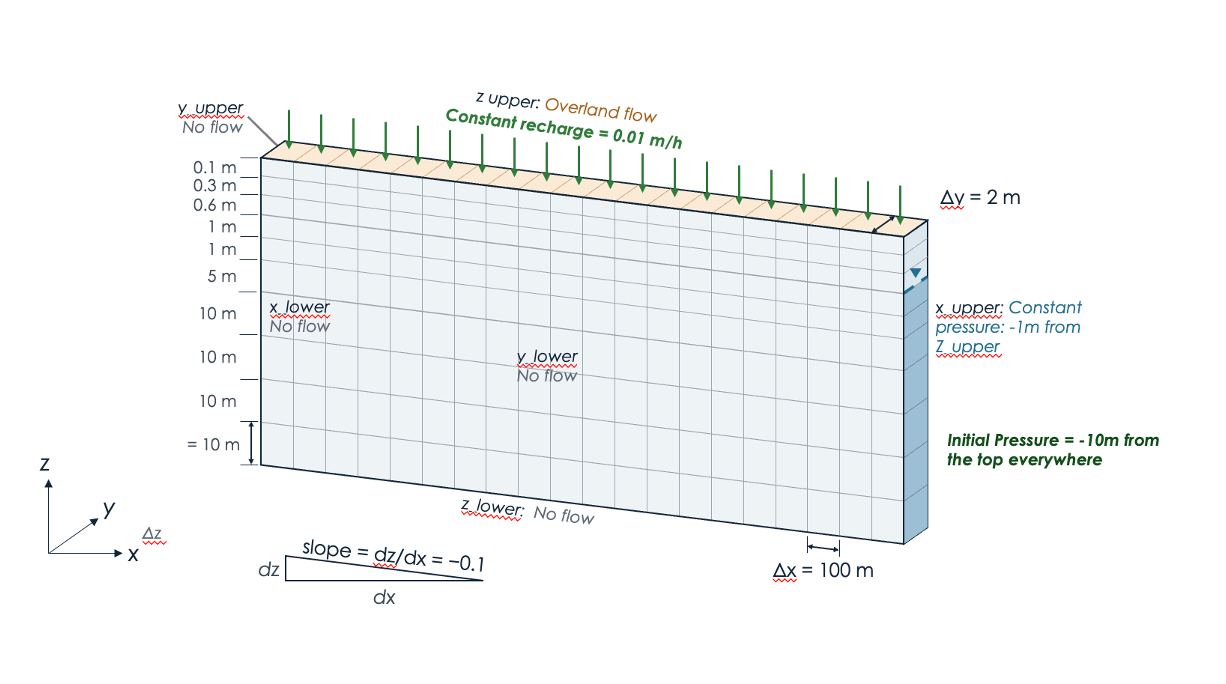




In [1]:
# Import the ParFlow package
from parflow import Run
import os
import sys
from parflow.tools.fs import mkdir, cp, chdir, get_absolute_path, rm, exists

# Import functions for plotting
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../utils")))
from plots import plot_domain

# 1. Load in the database from a previous run and look at its configuration

In [11]:
#set the output directory 
pf_runname  = "Test2"
base = os.path.join(os.getcwd(), "box_runs", pf_runname )

# Import run information from pfidb
domain_example = Run.from_definition(os.path.join(base, f"{pf_runname}.pfidb"))

Here is a summary of some of the main propertie of the model 

In [12]:
# Look at how the run is setup
pfidb_keys = domain_example.to_dict()
run_summary = {
    "Run name": domain_example.get_name(),
    "Number of configured keys": len(domain_example.to_dict()),
    "Grid dimensions (NX, NY, NZ)": (
        domain_example.ComputationalGrid.NX,
        domain_example.ComputationalGrid.NY,
        domain_example.ComputationalGrid.NZ,
    ),
    "Grid spacing (DX, DY, DZ)": (
        domain_example.ComputationalGrid.DX,
        domain_example.ComputationalGrid.DY,
        domain_example.ComputationalGrid.DZ,
    ),
    "Variable DZ scalers": [
        pfidb_keys[f"Cell.{layer}.dzScale.Value"]
        for layer in range(domain_example.ComputationalGrid.NZ)
    ],
    "Simulation start time": domain_example.TimingInfo.StartTime,
    "Simulation stop time": domain_example.TimingInfo.StopTime,
    "Domain porosity": domain_example.Geom.domain.Porosity.Value,
    "Permeability": domain_example.Geom.domain.Perm.Value,
}

for label, value in run_summary.items():
    print(f"{label}: {value}")

Run name: Test2
Number of configured keys: 157
Grid dimensions (NX, NY, NZ): (20, 1, 10)
Grid spacing (DX, DY, DZ): (100.0, 2.0, 1.0)
Variable DZ scalers: [10.0, 10.0, 10.0, 10.0, 5.0, 1.0, 1.0, 0.6, 0.3, 0.1]
Simulation start time: 0.0
Simulation stop time: 100.0
Domain porosity: 0.25
Permeability: 0.01465


You can look at all the keys that were set like this:

In [13]:
for key, value in sorted(pfidb_keys.items()):
    print(f"{key}: {value}")

BCPressure.PatchNames: x_lower x_upper y_lower y_upper z_lower z_upper
Cell.0.dzScale.Value: 10.0
Cell.1.dzScale.Value: 10.0
Cell.2.dzScale.Value: 10.0
Cell.3.dzScale.Value: 10.0
Cell.4.dzScale.Value: 5.0
Cell.5.dzScale.Value: 1.0
Cell.6.dzScale.Value: 1.0
Cell.7.dzScale.Value: 0.6
Cell.8.dzScale.Value: 0.3
Cell.9.dzScale.Value: 0.1
ComputationalGrid.DX: 100.0
ComputationalGrid.DY: 2.0
ComputationalGrid.DZ: 1.0
ComputationalGrid.Lower.X: 0.0
ComputationalGrid.Lower.Y: 0.0
ComputationalGrid.Lower.Z: 0.0
ComputationalGrid.NX: 20
ComputationalGrid.NY: 1
ComputationalGrid.NZ: 10
Contaminants.Names: 
Cycle.Names: constant
Cycle.constant.Names: alltime
Cycle.constant.Repeat: -1
Cycle.constant.alltime.Length: 1
Domain.GeomName: domain
FileVersion: 4
Geom.Perm.Names: domain
Geom.Perm.TensorByGeom.Names: domain
Geom.Porosity.GeomNames: domain
Geom.domain.ICPressure.RefGeom: domain
Geom.domain.ICPressure.RefPatch: z_upper
Geom.domain.ICPressure.Value: -10.0
Geom.domain.Lower.X: 0.0
Geom.domain.L

You can print out any key from the database by calling its name the same way you would if you were setting it. 

In [14]:
print(domain_example.ComputationalGrid.DX)

100.0


# 2. Change the name and a key and run a new simulation 

Now lets change the run name and one key in the database and run a new simulation. For our example lets change the number of cells in X from 20 to 50. 

In [17]:
new_name = 'box_db_test'
domain_example.set_name(new_name)
domain_example.ComputationalGrid.NX  = 50

print(domain_example.get_name())

#-----------------------------------------------------------------------------
# Run ParFlow
#-----------------------------------------------------------------------------
base = os.path.join(os.getcwd(), "box_runs", domain_example.get_name() )
mkdir(base)
print(f"base: {base}")

## This is the line that actually calls parflow to run!
domain_example.run(working_directory=base)

box_db_test
base: /workspaces/ParFlow_CUAHSI_VU/my_work/box_runs/box_db_test
: Field _run_file is not part of the expected schema <class 'parflow.tools.core.Run'>

# ==============================================================================
# ParFlow directory
#  - /opt/parflow/
# ParFlow version
#  - 3.15.0
# Working directory
#  - /workspaces/ParFlow_CUAHSI_VU/my_work/box_runs/box_db_test
# ParFlow database
#  - box_db_test.pfidb
# ==============================================================================


# ==============================================================================
# ParFlow ran successfully
# ==============================================================================

